In [15]:
import os

In [2]:
if 'COLAB_GPU' in os.environ or not os.path.exists('utils') or not os.path.exists('data'):
    print("📥 Downloading required files...")
    !wget -q https://github.com/Alireza-Akhavan/Agentic_AI/raw/refs/heads/main/utils/llm_helpers.py -P utils
    !wget -q https://github.com/Alireza-Akhavan/Agentic_AI/raw/refs/heads/main/data/coffee_sales.csv -P data
    !pip install -q anthropic
    print("✅ Setup completed")
else:
    print("✅ Running locally - using existing files")

✅ Running locally - using existing files


In [16]:
# Standard library imports
import re
import json
import pandas as pd
# Local helper module
from utils import llm_helpers as utils

In [17]:
# Use this utils.py function to load the data into a dataframe
df = utils.load_and_prepare_data('data/coffee_sales.csv')

# Grab a random sample to display
utils.print_html(df.sample(n=5), title="Random Sample of Coffee Sales Data")

date,time,cash_type,card,price,coffee_name,quarter,month,year
2024-03-28,14:07,card,ANON-0000-0000-0012,2.890,Cortado,1,3,2024
2024-10-15,11:05,card,ANON-0000-0000-0767,2.596,Americano,4,10,2024
2024-03-01,06:14,card,ANON-0000-0000-0001,3.870,Latte,1,3,2024
2024-09-27,07:34,card,ANON-0000-0000-0674,3.282,Cappuccino,3,9,2024
2024-05-14,07:23,card,ANON-0000-0000-0012,2.792,Americano,2,5,2024


In [18]:
def get_df_schema_string(df: pd.DataFrame) -> str:
    """ It will get schema"""
    buffer = []
    buffer.append("DataFrame Columns and Data Types:")
    for col, dtype in df.dtypes.items():
        buffer.append(f"- {col} ({dtype})")
    
    buffer.append("\nFirst 2 rows sample:")
    buffer.append(df.head(2).to_string(index=False))
    
    return "\n".join(buffer)

# get_df_schema_string(df)

In [19]:
def generate_chart_code(instruction: str, model: str, out_path_v1: str, df: pd.DataFrame) -> str:
    """Generate Python code using dynamic schema extraction."""

    schema_info = f"""
    DataFrame Schema (variable name is 'df'):
    Columns and Types:
    {df.dtypes.to_string()}

    Data Sample (First 2 rows):
    {df.head(2).to_string()}
    """

    prompt = f"""
    You are a data visualization expert.

    Return your answer *strictly* in this format:

    <execute_python>
    # valid python code here
    </execute_python>

    Do not add explanations, only the tags and the code.

    {schema_info}

    User instruction: {instruction}

    Requirements for the code:
    1. Assume the DataFrame is already loaded as 'df'.
    2. Use matplotlib for plotting.
    3. Add clear title, axis labels, and legend if needed.
    4. Save the figure as '{out_path_v1}' with dpi=300.
    5. Do not call plt.show().
    6. Close all plots with plt.close().
    7. Add all necessary import python statements

    Return ONLY the code wrapped in <execute_python> tags.
    """

    response = utils.get_response(model, prompt)
    return response

In [20]:
# Generate initial code
code_v1 = generate_chart_code(
    instruction="Create a plot comparing Q1 coffee sales in 2024 and 2025 using the data in coffee_sales.csv.",
    model="gemini-2.5-flash-lite",
    out_path_v1="chart_v1.png",
    df = df
)

utils.print_html(code_v1, title="LLM output with first draft code")


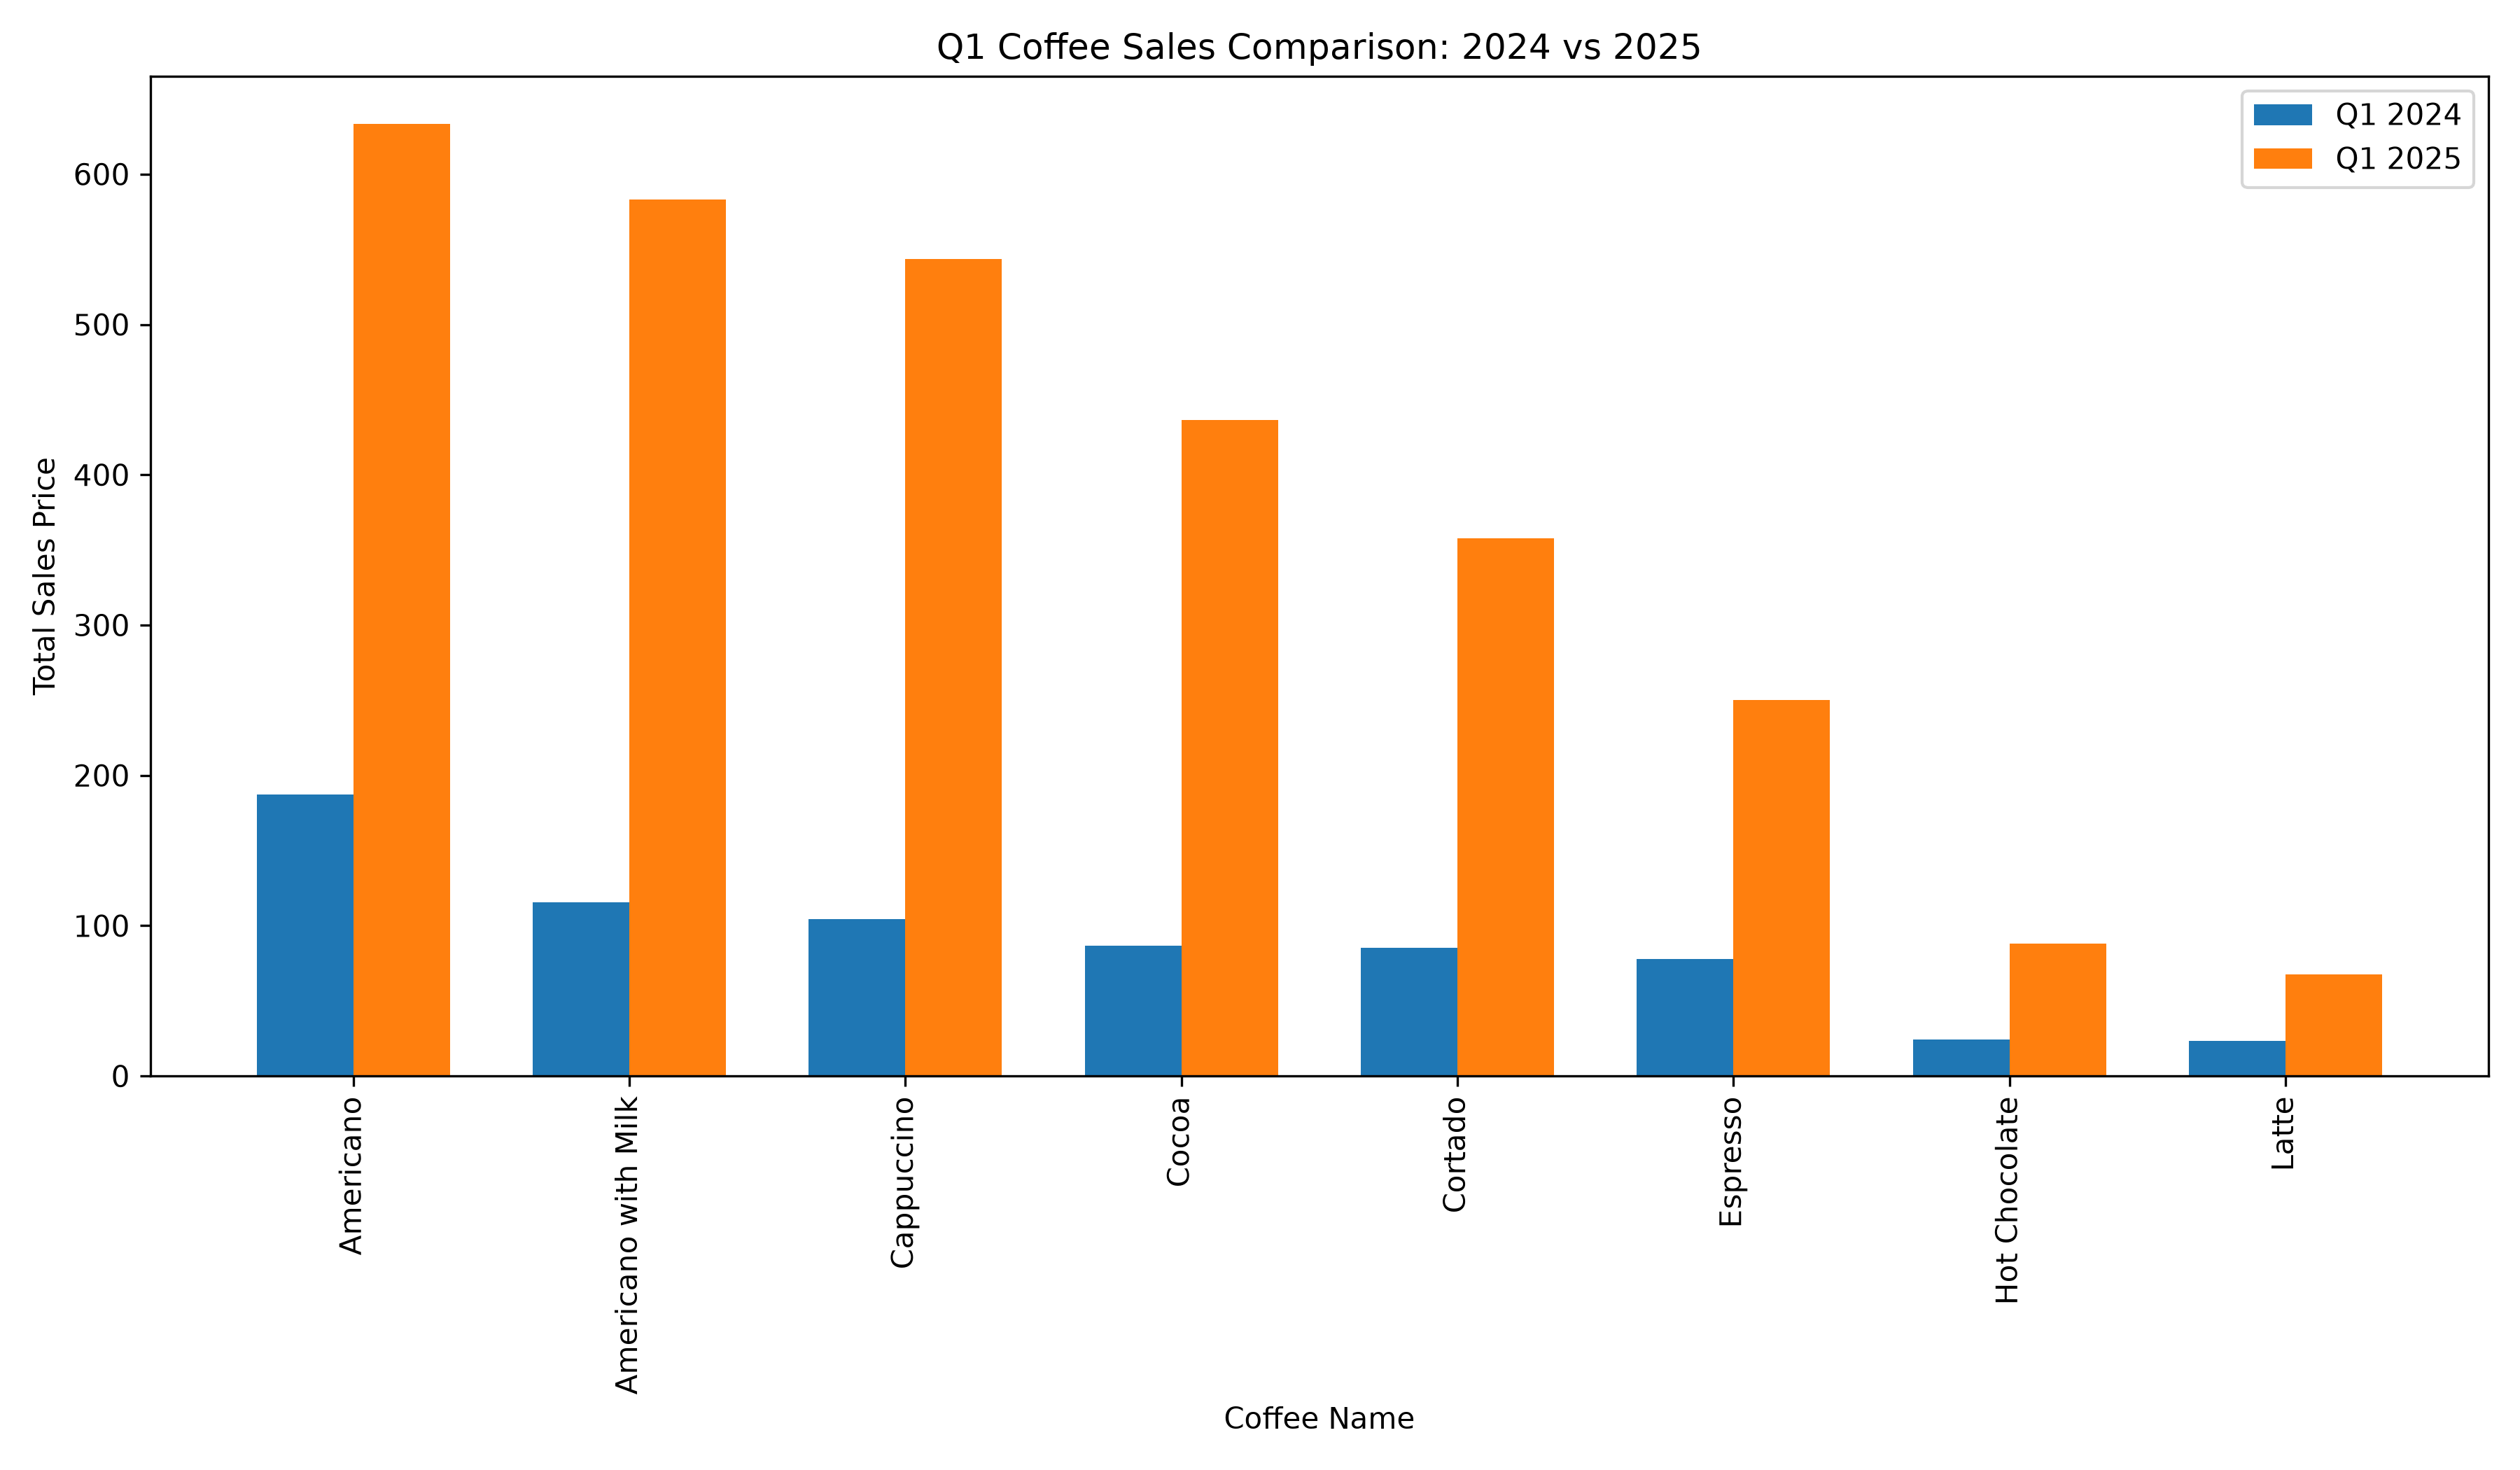

In [21]:
# Get the code within the <execute_python> tags
match = re.search(r"<execute_python>([\s\S]*?)</execute_python>", code_v1)
if match:
    initial_code = match.group(1).strip()
    utils.print_html(initial_code, title="Extracted Code to Execute")
    exec_globals = {"df": df}
    exec(initial_code, exec_globals)

# If code run successfully, the file chart_v1.png should have been generated
utils.print_html(
    content="chart_v1.png",
    title="Generated Chart (V1)",
    is_image=True
)

In [22]:
def reflect_on_image_and_regenerate(
    chart_path: str,
    instruction: str,
    model_name: str,
    out_path_v2: str,
    code_v1: str,
    df: pd.DataFrame, 
) -> tuple[str, str]:

    media_type, b64 = utils.encode_image_b64(chart_path)

    schema_info = f"""
    Schema and Sample Data (available in 'df'):
    {df.dtypes.to_string()}
    
    First 2 rows preview:
    {df.head(2).to_string()}
    """

    prompt = f"""
    You are a data visualization expert.
    Your task: critique the attached chart and the original code against the given instruction,
    then return improved matplotlib code.

    Original code (for context):
    {code_v1}

    OUTPUT FORMAT (STRICT):
    1) First line: a valid JSON object with ONLY the "feedback" field.
    Example: {{"feedback": "The legend is unclear and the axis labels overlap."}}

    2) After a newline, output ONLY the refined Python code wrapped in:
    <execute_python>
    ...
    </execute_python>

    3) Import all necessary libraries in the code. Don't assume any imports from the original code.

    HARD CONSTRAINTS:
    - Do NOT include Markdown, backticks, or any extra prose outside the two parts above.
    - Use pandas/matplotlib only (no seaborn).
    - Assume df already exists; do not read from files.
    - Save to '{out_path_v2}' with dpi=300.
    - Always call plt.close() at the end (no plt.show()).
    - Include all necessary import statements.

    {schema_info}

    Instruction:
    {instruction}
    """


    # In case the name is "Claude" or "Anthropic", use the safe helper
    lower = model_name.lower()
    if "claude" in lower or "anthropic" in lower:
        # ✅ Use the safe helper that joins all text blocks and adds a system prompt
        content = utils.image_anthropic_call(model_name, prompt, media_type, b64)
    else:
        content = utils.image_openai_call(model_name, prompt, media_type, b64)

    # --- Parse ONLY the first JSON line (feedback) ---
    lines = content.strip().splitlines()
    json_line = lines[0].strip() if lines else ""

    try:
        obj = json.loads(json_line)
    except Exception as e:
        # Fallback: try to capture the first {...} in all the content
        m_json = re.search(r"\{.*?\}", content, flags=re.DOTALL)
        if m_json:
            try:
                obj = json.loads(m_json.group(0))
            except Exception as e2:
                obj = {"feedback": f"Failed to parse JSON: {e2}", "refined_code": ""}
        else:
            obj = {"feedback": f"Failed to find JSON: {e}", "refined_code": ""}

    # --- Extract refined code from <execute_python>...</execute_python> ---
    m_code = re.search(r"<execute_python>([\s\S]*?)</execute_python>", content)
    refined_code_body = m_code.group(1).strip() if m_code else ""
    refined_code = utils.ensure_execute_python_tags(refined_code_body)

    feedback = str(obj.get("feedback", "")).strip()
    return feedback, refined_code



In [23]:
# Generate feedback alongside reflected code
feedback, code_v2 = reflect_on_image_and_regenerate(
    chart_path="chart_v1.png",
    instruction="Create a plot comparing Q1 coffee sales in 2024 and 2025 using the data in coffee_sales.csv.",
    model_name="gemini-2.5-flash-lite",
    out_path_v2="chart_v2.png",
    code_v1=code_v1,   # pass in the original code for context
    df = df
)

utils.print_html(feedback, title="Feedback on V1 Chart")
utils.print_html(code_v2, title="Regenerated Code Output (V2)")


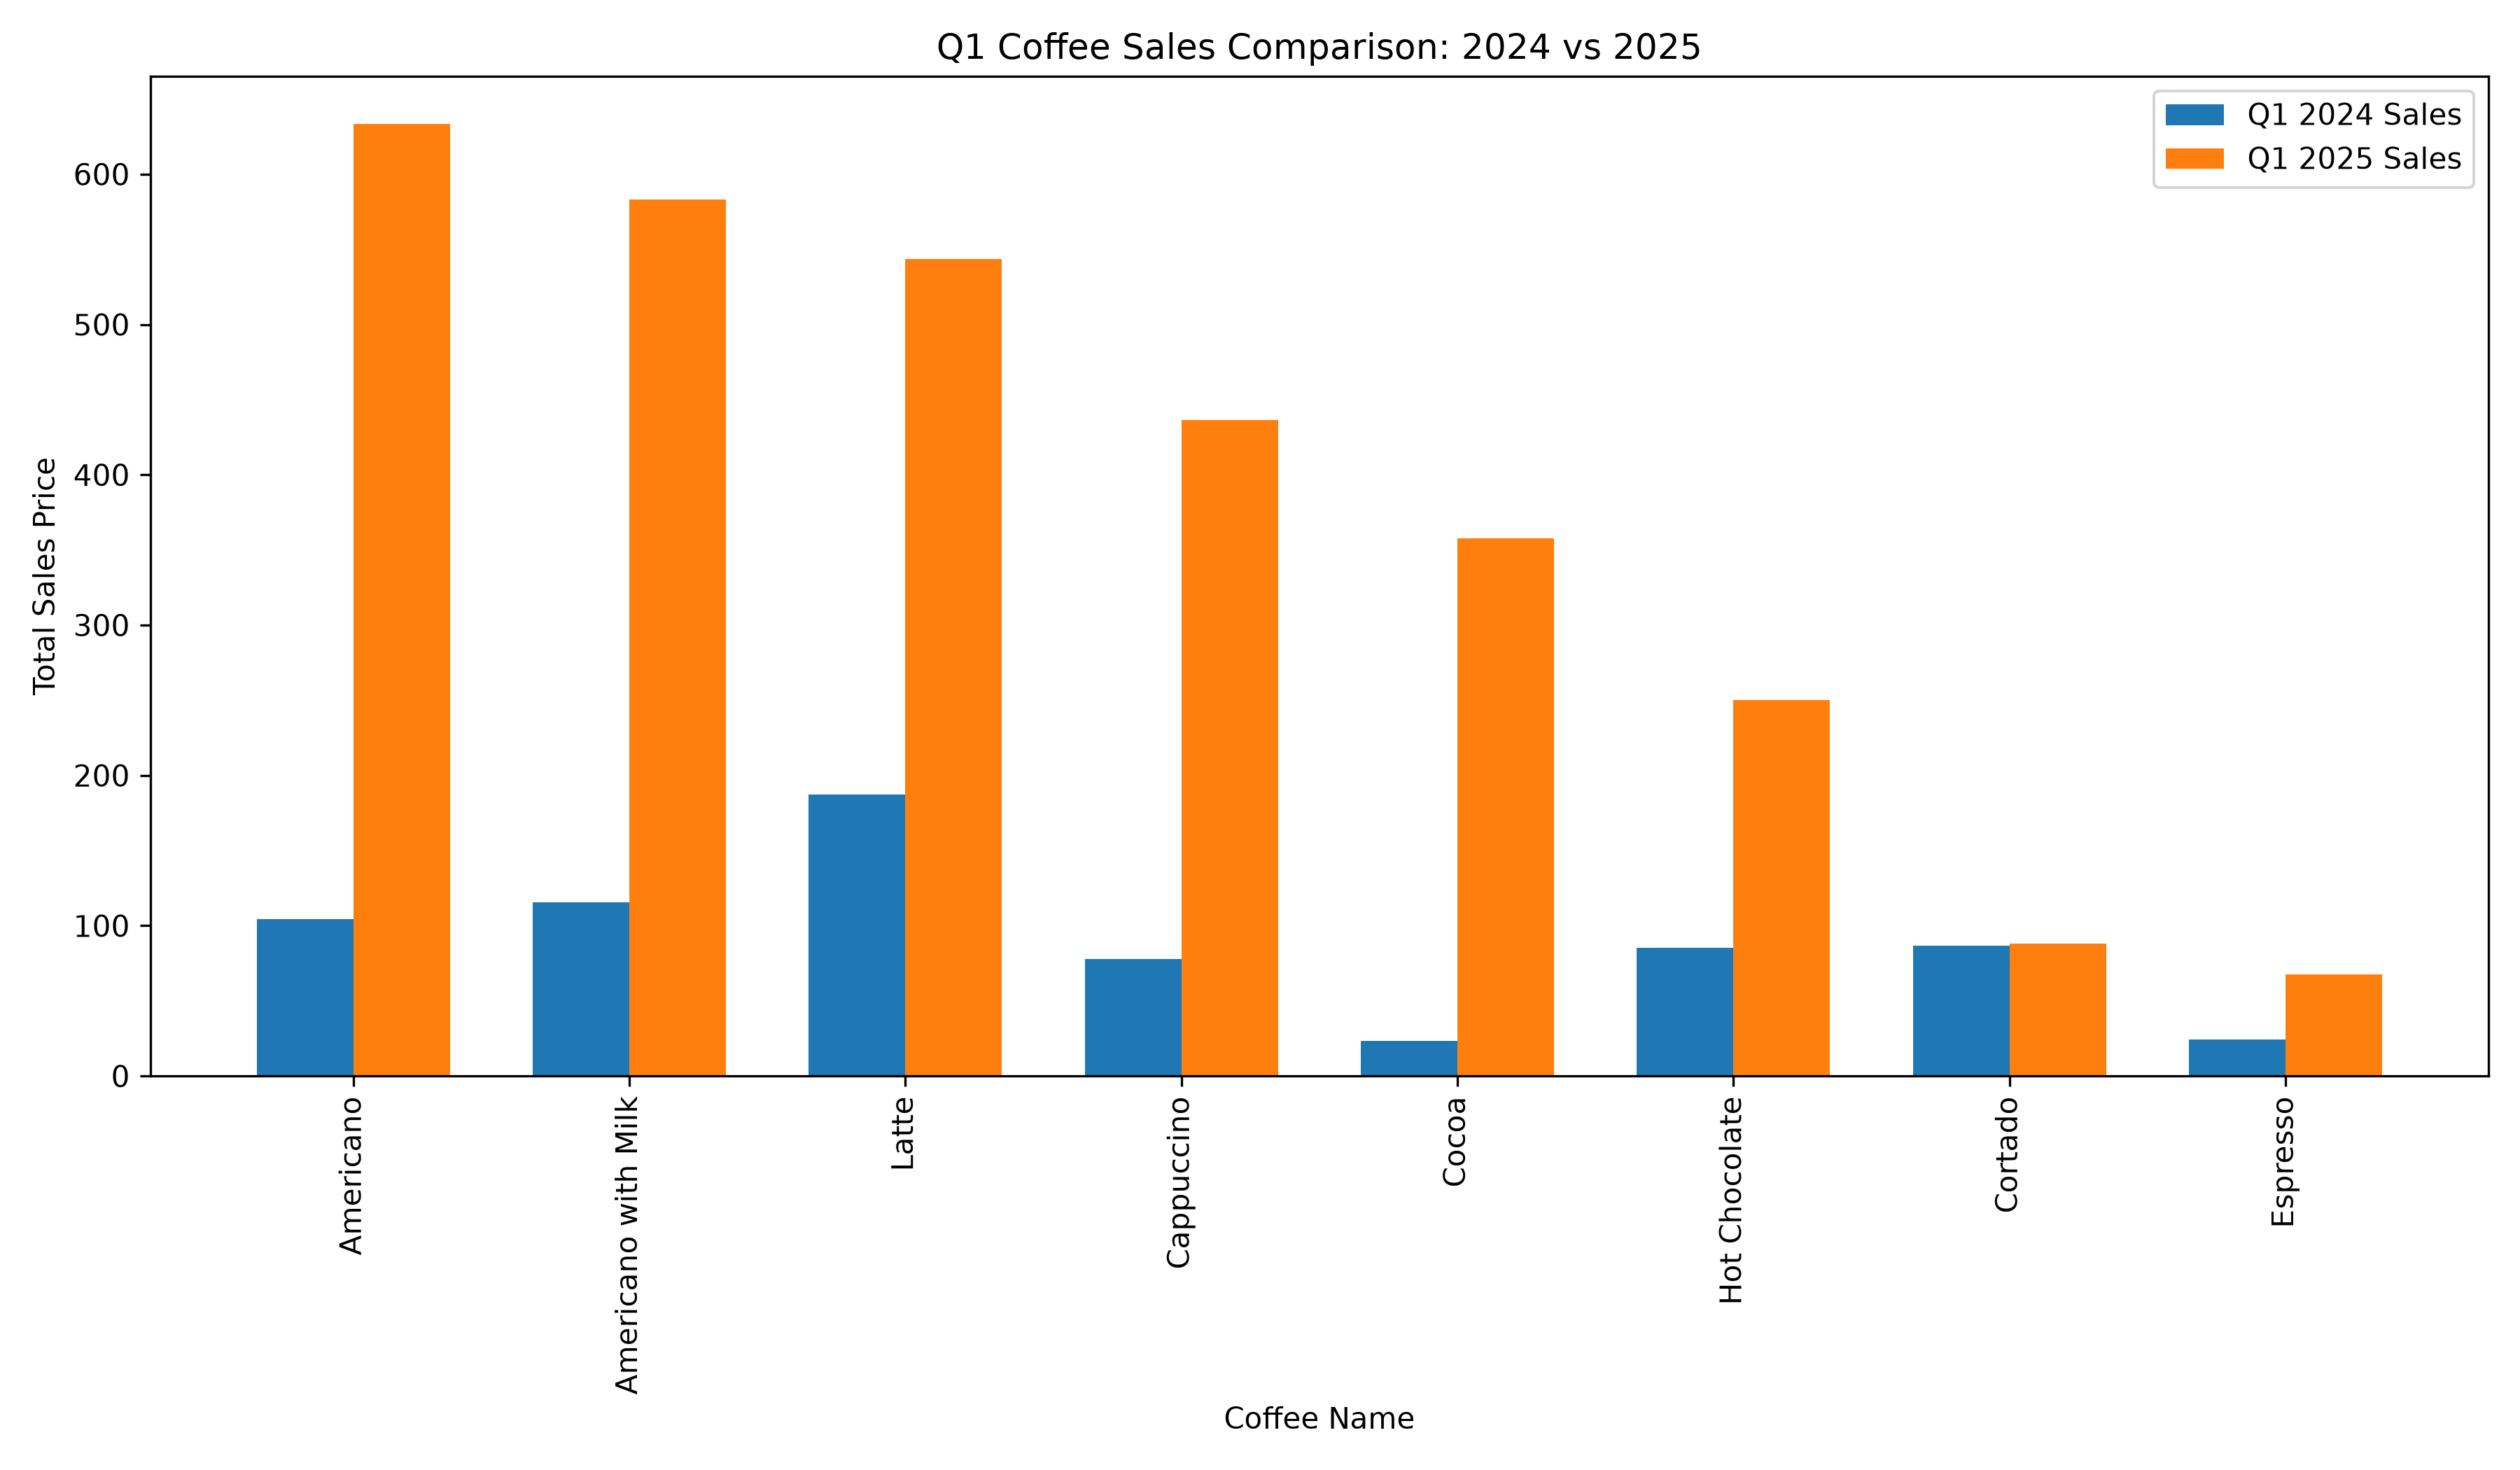

In [24]:
# Get the code within the <execute_python> tags
match = re.search(r"<execute_python>([\s\S]*?)</execute_python>", code_v2)
if match:
    reflected_code = match.group(1).strip()
    exec_globals = {"df": df}
    exec(reflected_code, exec_globals)

# If code run successfully, the file chart_v2.png should have been generated
utils.print_html(
    content="chart_v2.png",
    title="Regenerated Chart (V2)",
    is_image=True
)